# Que1.-
### Predict if a person would buy life insurance based on his age using logistic regression.
### About Dataset - Age: Age of a person
### bought_insurance : whether person buys Insurance or not (0 - No, 1 - Yes)
### predict it for Age : 58,30,20,49,53

#### Dataset : insurance_data.csv

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
df=pd.read_csv("insurance_data.csv")
df.head()

,age,bought_insurance
0,22,0
1,25,0
2,47,1
3,52,0
4,46,1


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   age               27 non-null     int64
 1   bought_insurance  27 non-null     int64
dtypes: int64(2)
memory usage: 560.0 bytes


In [41]:
df.describe()

,age,bought_insurance
count,27.000000,27.000000
mean,39.666667,0.518519
std,15.745573,0.509175
min,18.000000,0.000000
25%,25.000000,0.000000
50%,45.000000,1.000000
75%,54.500000,1.000000
max,62.000000,1.000000


In [42]:
df.corr()

,age,bought_insurance
age,1.000000,0.732395
bought_insurance,0.732395,1.000000


<Axes: >

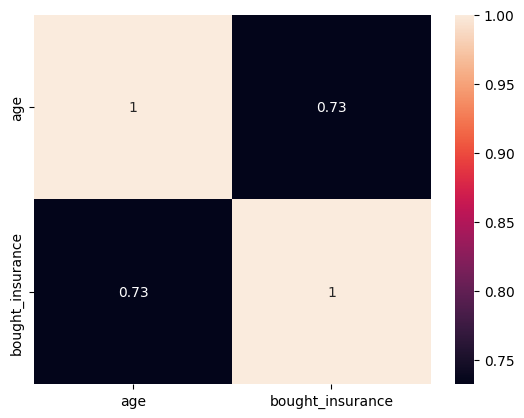

In [43]:
sns.heatmap(df.corr(),annot=True)

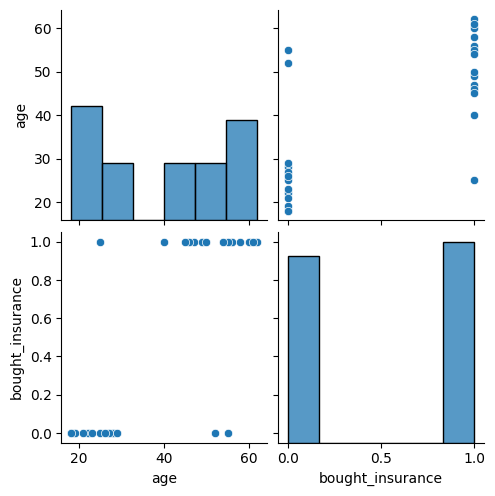

In [44]:
sns.pairplot(df)

In [45]:
df['bought_insurance'].value_counts()

bought_insurance
1    14
0    13
Name: count, dtype: int64

In [46]:
X=df.drop('bought_insurance',axis=1)
y=df['bought_insurance']

In [48]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
        X,y,train_size=0.7, random_state=42
)

In [49]:
from sklearn.linear_model import LogisticRegressionCV
model=LogisticRegressionCV()
model.fit(X_train,y_train)

LogisticRegressionCV()

In [51]:
y_pred=model.predict(X_train)

from sklearn.metrics import classification_report
print(classification_report(y_train,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.75      0.86         8
           1       0.83      1.00      0.91        10

    accuracy                           0.89        18
   macro avg       0.92      0.88      0.88        18
weighted avg       0.91      0.89      0.89        18



In [52]:
y_pred=model.predict(X_test)
y_pred

array([1, 0, 1, 0, 0, 0, 0, 1, 0], dtype=int64)

In [53]:
model.predict_proba(X_test)

array([[0.24378001, 0.75621999],
       [0.5642422 , 0.4357578 ],
       [0.2516313 , 0.7483687 ],
       [0.59503094, 0.40496906],
       [0.63491101, 0.36508899],
       [0.57457262, 0.42542738],
       [0.60514225, 0.39485775],
       [0.27617297, 0.72382703],
       [0.58483834, 0.41516166]])

In [50]:
score=model.score(X_test,y_test)
print(f"score={score*100:2f}%")

score=88.888889%


In [54]:
y_pred=model.predict(X_test)
y_pred

array([1, 0, 1, 0, 0, 0, 0, 1, 0], dtype=int64)

In [55]:
model.predict_proba(X_test)

array([[0.24378001, 0.75621999],
       [0.5642422 , 0.4357578 ],
       [0.2516313 , 0.7483687 ],
       [0.59503094, 0.40496906],
       [0.63491101, 0.36508899],
       [0.57457262, 0.42542738],
       [0.60514225, 0.39485775],
       [0.27617297, 0.72382703],
       [0.58483834, 0.41516166]])

In [56]:
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
cm

array([[5, 0],
       [1, 3]], dtype=int64)

In [58]:
tn,fp,fn,tp=cm.ravel()
print(f"tn:{tn},fp:{fp},fn:{fn},tp:{tp}")

tn:5,fp:0,fn:1,tp:3


In [59]:
accuracy=(tp+tn)/(tp+tn+fp+fn)
print(f"accuracy={accuracy*100:.2f}%")

accuracy=88.89%


In [60]:
from sklearn.metrics import accuracy_score

accuracy=accuracy_score(y_test,y_pred)
print(f"accuracy={accuracy*100:.2f}%")

accuracy=88.89%


In [61]:
precision_positive=tp/(tp+fp)
print(f"precision positive={precision_positive*100:.2f}%")

precision positive=100.00%


In [62]:
precision_negative=tn/(tn+fn)
print(f"precision negative ={precision_negative*100:.2f}")

precision negative =83.33


In [63]:
from sklearn.metrics import precision_score
precision=precision_score(y_test,y_pred)
print(f"precision positive ={precision * 100:.2f}%")

precision positive =100.00%


In [64]:
recall_positive=tp/(tp+fn)
print(f"recall positive ={recall_positive * 100:.2f}%")

recall positive =75.00%


In [65]:
recall_negative = tn / (tn + fp)
print(f"recall negative = {recall_negative * 100:.2f}%")

recall negative = 100.00%


In [66]:
from sklearn.metrics import recall_score
recall = recall_score(y_test, y_pred)
print(f"positice recall = {recall * 100: .2f}%")

positice recall =  75.00%


In [67]:
f1_positive = 2 * ((precision_positive * recall_positive) / (precision_positive + recall_positive))
print(f"positive F1 score = {f1_positive:.2f}")

positive F1 score = 0.86


In [69]:
f1_negative = 2 * ((precision_negative * recall_negative) / (precision_negative + recall_negative))
print(f"negative F1 score = {f1_negative:.2f}")

negative F1 score = 0.91


In [70]:
from sklearn.metrics import f1_score
f1 = f1_score(y_test, y_pred)
print(f"positive f1 score = {f1:.2f}")

positive f1 score = 0.86


In [71]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      1.00      0.91         5
           1       1.00      0.75      0.86         4

    accuracy                           0.89         9
   macro avg       0.92      0.88      0.88         9
weighted avg       0.91      0.89      0.89         9



In [72]:
model.predict([[58],[30],[20],[49],[53]])

C:\Users\neham\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegressionCV was fitted with feature names
  warnings.warn(


array([1, 0, 0, 1, 1], dtype=int64)